# imports

In [34]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [35]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [36]:
# specific
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

In [37]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_worm_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../../worm-control/src/utils_worm_control/read_utils.py'>

# setup

In [38]:
ll = 'll00'
data_variant = 'gcamp'

save = True

In [39]:
# specific

# model_variant = 'ss, ns'
organism = 'mouse'
manual = False
full = False

In [40]:
file_ids = list(range(0, 17+1))
# file_ids = [19]

# load

In [41]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filenames = analysis_utils.read_filenames(organism, file_ids)

In [42]:
neuron_numbers = list()
for file_id in file_ids:
	filename, traces, markers, classes, timestamps, aux = analysis_utils.read_data(organism, file_id)
	neuron_numbers.append(traces.values.shape[1])
filename, traces, markers, classes, timestamps, aux = None, None, None, None, None, None

# scores (ns)

In [43]:
significant_neurons_ns = list()
for filename in filenames:
	significant_neurons_ns.append(pd.read_csv(f'../../out/data/significant_neurons/{filename}/ns_model.csv'))

/tmp/ipykernel_47598/1506050629.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])


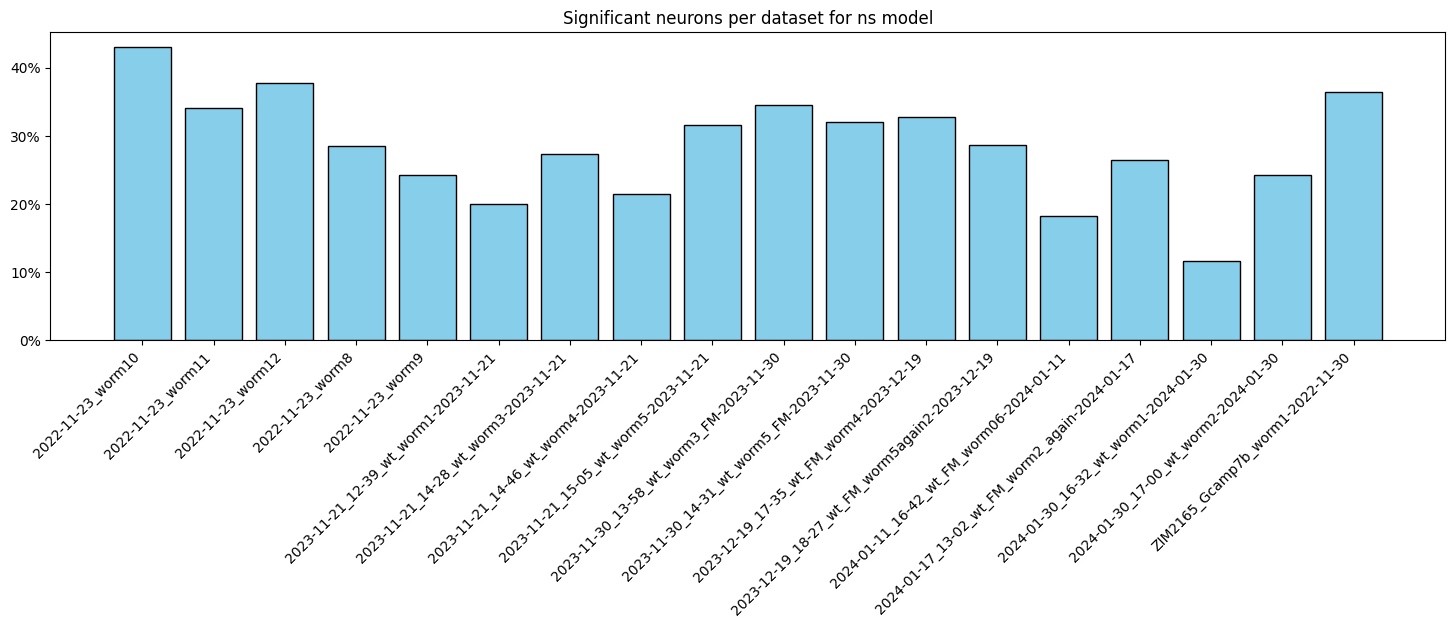

In [44]:
plt.figure(figsize=(1*len(filenames), 4))
plt.bar(np.arange(len(filenames)), [neurons.values.shape[1] / n * 100 for neurons, n in zip(significant_neurons_ns, neuron_numbers)], color='skyblue' , edgecolor='black')
plt.xticks(np.arange(len(filenames)), filenames, rotation=45, ha='right')
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])
plt.title('Significant neurons per dataset for ns model')
if save:
	plt.savefig('../../out/plots/scores/significant_neurons_ns.png', bbox_inches='tight')

# scores (ss)

In [45]:
significant_neurons_ss = list()
for filename in filenames:
	significant_neurons_ss.append(pd.read_csv(f'../../out/data/significant_neurons/{filename}/ss_model.csv'))

/tmp/ipykernel_47598/1998525158.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])


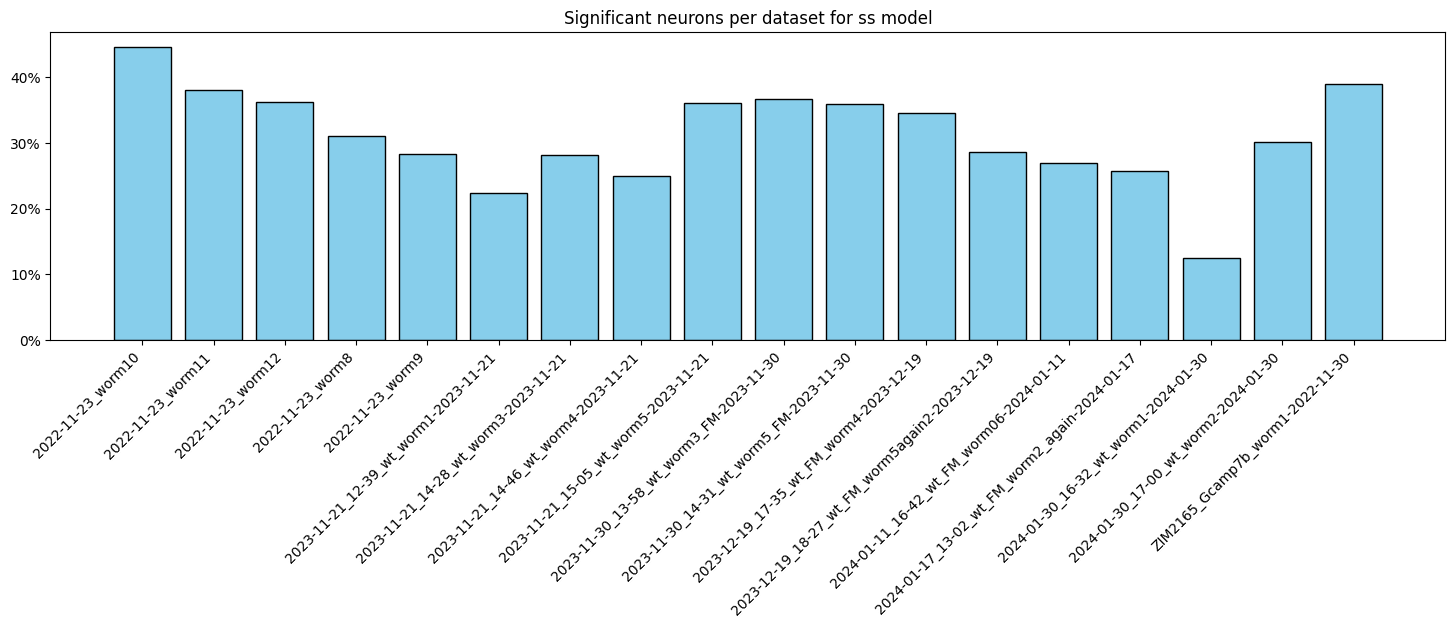

In [46]:
plt.figure(figsize=(1*len(filenames), 4))
plt.bar(np.arange(len(filenames)), [neurons.values.shape[1] / n * 100 for neurons, n in zip(significant_neurons_ss, neuron_numbers)], color='skyblue' , edgecolor='black')
plt.xticks(np.arange(len(filenames)), filenames, rotation=45, ha='right')
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])
plt.title('Significant neurons per dataset for ss model')
if save:
	plt.savefig('../../out/plots/scores/significant_neurons_ss.png', bbox_inches='tight')